In [2]:
import pandas as pd
import numpy as np

# Données entièrement fictives : demandes de prêts à la consommation
rng = np.random.default_rng(2026)
n = 8000

age = rng.integers(18, 76, n)
revenu_annuel = np.clip(rng.lognormal(10.45, 0.45, n), 12000, 250000).round(0)
montant_pret = np.clip(rng.lognormal(9.4, 0.7, n), 1000, 75000).round(-2)
duree_mois = rng.choice([12, 24, 36, 48, 60, 72, 84], n, p=[0.08, 0.17, 0.22, 0.2, 0.18, 0.09, 0.06])
situation_pro = rng.choice(
    ["CDI", "CDD", "Indépendant", "Sans emploi", "Retraité"], n,
    p=[0.55, 0.13, 0.12, 0.05, 0.15],
)
statut_logement = rng.choice(["Propriétaire", "Locataire", "Hébergé"], n, p=[0.45, 0.45, 0.10])
nb_incidents_passes = rng.poisson(0.3, n)
nb_credits_en_cours = rng.poisson(0.8, n)
anciennete_banque_ans = rng.integers(0, 31, n)

# Une banque ne prête pas au-delà d'une mensualité de 60 % du revenu mensuel
montant_pret = np.minimum(montant_pret, 0.6 * revenu_annuel / 12 * duree_mois).round(-2)

# Probabilité de défaut (règle cachée que le modèle devra retrouver)
mensualite = montant_pret / duree_mois
endettement = mensualite / (revenu_annuel / 12)
logit = (
    -3.9
    + 5.0 * endettement
    + 0.75 * nb_incidents_passes
    + 0.25 * nb_credits_en_cours
    + 0.6 * (situation_pro == "CDD")
    + 0.5 * (situation_pro == "Indépendant")
    + 1.3 * (situation_pro == "Sans emploi")
    + 0.3 * (statut_logement == "Locataire")
    - 0.035 * anciennete_banque_ans
    - 0.012 * (age - 40)
)
prob = 1 / (1 + np.exp(-logit))
defaut = rng.binomial(1, prob)

df = pd.DataFrame({
    "age": age,
    "revenu_annuel": revenu_annuel,
    "montant_pret": montant_pret,
    "duree_mois": duree_mois,
    "situation_pro": situation_pro,
    "statut_logement": statut_logement,
    "nb_incidents_passes": nb_incidents_passes,
    "nb_credits_en_cours": nb_credits_en_cours,
    "anciennete_banque_ans": anciennete_banque_ans,
    "defaut": defaut,
})

# Défauts volontaires à corriger
for col, frac in [("revenu_annuel", 0.04), ("situation_pro", 0.03), ("anciennete_banque_ans", 0.02)]:
    idx = rng.choice(df.index, size=int(n * frac), replace=False)
    df.loc[idx, col] = np.nan

df = pd.concat([df, df.sample(15, random_state=2026)], ignore_index=True)

path = "prets_credit.csv"
df.to_csv(path, index=False)
print(path, df.shape, df["defaut"].value_counts().to_dict())

prets_credit.csv (8015, 10) {0: 7372, 1: 643}


In [3]:
df = pd.read_csv("prets_credit.csv")
df.head()

,age,revenu_annuel,montant_pret,duree_mois,situation_pro,statut_logement,nb_incidents_passes,nb_credits_en_cours,anciennete_banque_ans,defaut
0,67,104543.0,6900.0,48,CDI,Propriétaire,0,0,6.0,0
1,28,59310.0,13800.0,36,Sans emploi,Propriétaire,0,0,0.0,0
2,19,74446.0,37900.0,48,Indépendant,Propriétaire,1,0,9.0,0
3,55,NaN,36200.0,60,CDI,Locataire,1,0,29.0,0
4,39,42943.0,9100.0,36,CDD,Propriétaire,0,1,5.0,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8015 entries, 0 to 8014
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    8015 non-null   int64  
 1   revenu_annuel          7695 non-null   float64
 2   montant_pret           8015 non-null   float64
 3   duree_mois             8015 non-null   int64  
 4   situation_pro          7775 non-null   str    
 5   statut_logement        8015 non-null   str    
 6   nb_incidents_passes    8015 non-null   int64  
 7   nb_credits_en_cours    8015 non-null   int64  
 8   anciennete_banque_ans  7854 non-null   float64
 9   defaut                 8015 non-null   int64  
dtypes: float64(3), int64(5), str(2)
memory usage: 626.3 KB


In [5]:
df["defaut"].value_counts(normalize=True)

defaut
0    0.919775
1    0.080225
Name: proportion, dtype: float64

In [6]:
df.describe()

,age,revenu_annuel,montant_pret,duree_mois,nb_incidents_passes,nb_credits_en_cours,anciennete_banque_ans,defaut
count,8015.000000,7695.000000,8015.000000,8015.000000,8015.000000,8015.000000,7854.000000,8015.000000
mean,46.411104,38288.470825,15017.691828,44.541485,0.299439,0.799376,14.969697,0.080225
std,16.744719,18108.098957,10982.058282,19.428116,0.543738,0.891506,9.006886,0.271658
min,18.000000,12000.000000,1000.000000,12.000000,0.000000,0.000000,0.000000,0.000000
25%,32.000000,25322.000000,7500.000000,24.000000,0.000000,0.000000,7.000000,0.000000
50%,46.000000,34808.000000,12000.000000,48.000000,0.000000,1.000000,15.000000,0.000000
75%,61.000000,46992.000000,19100.000000,60.000000,1.000000,1.000000,23.000000,0.000000
max,75.000000,179940.000000,75000.000000,84.000000,5.000000,6.000000,30.000000,1.000000


In [7]:
df.isna().sum()

age                        0
revenu_annuel            320
montant_pret               0
duree_mois                 0
situation_pro            240
statut_logement            0
nb_incidents_passes        0
nb_credits_en_cours        0
anciennete_banque_ans    161
defaut                     0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(15)

In [9]:
df.nunique()

age                        58
revenu_annuel            7048
montant_pret              550
duree_mois                  7
situation_pro               5
statut_logement             3
nb_incidents_passes         5
nb_credits_en_cours         7
anciennete_banque_ans      31
defaut                      2
dtype: int64

In [10]:
df = df.drop_duplicates()
df.shape

(8000, 10)

In [11]:
x = df.drop("defaut", axis=1)
y = df["defaut"]

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
    

In [13]:
df.head()

,age,revenu_annuel,montant_pret,duree_mois,situation_pro,statut_logement,nb_incidents_passes,nb_credits_en_cours,anciennete_banque_ans,defaut
0,67,104543.0,6900.0,48,CDI,Propriétaire,0,0,6.0,0
1,28,59310.0,13800.0,36,Sans emploi,Propriétaire,0,0,0.0,0
2,19,74446.0,37900.0,48,Indépendant,Propriétaire,1,0,9.0,0
3,55,NaN,36200.0,60,CDI,Locataire,1,0,29.0,0
4,39,42943.0,9100.0,36,CDD,Propriétaire,0,1,5.0,0


In [14]:
numeric_features = [
    "age",
    "revenu_annuel",
    "montant_pret",
    "nb_incidents_passes",
    "nb_credits_en_cours",
    "anciennete_banque_ans"
]

categorical_features = [
    "duree_mois",
    "situation_pro",
    "statut_logement"
]

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [16]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer ,categorical_features)
    ]
)

In [18]:
from sklearn.linear_model import LogisticRegression

In [19]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

In [20]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['age','revenu_annuel','montant_pret',...,'nb_incidents_passes', 'nb_credits_en_cours','anciennete_banque_ans']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By s

In [21]:
model.named_steps["classifier"].n_iter_

array([33], dtype=int32)

In [22]:
y_pred = model.predict(X_test)
probas = model.predict_proba(X_test)[:,1]

print("Defaut prédits :", y_pred.sum())
print("Defaut réels :", y_test.sum())

Defaut prédits : 11
Defaut réels : 128


In [23]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Defaut prédits :", y_pred.sum())
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("AUC :", roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]))

Defaut prédits : 491
[[1064  408]
 [  45   83]]
              precision    recall  f1-score   support

           0       0.96      0.72      0.82      1472
           1       0.17      0.65      0.27       128

    accuracy                           0.72      1600
   macro avg       0.56      0.69      0.55      1600
weighted avg       0.90      0.72      0.78      1600

AUC : 0.762902301290761


<Axes: >

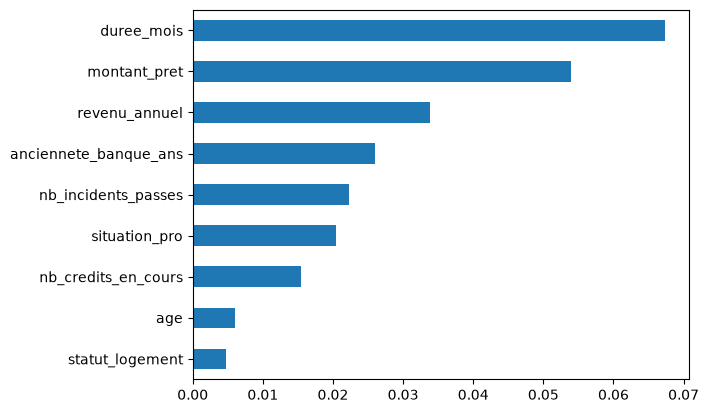

In [24]:
from sklearn.inspection import permutation_importance

result = permutation_importance(model, X_test, y_test, scoring="roc_auc",
                                n_repeats=10, random_state=42)
importances = pd.Series(result.importances_mean, index=X_test.columns).sort_values()
importances.plot(kind="barh")

=== Taux de défaut par durée ===
             taux  dossiers
duree_mois                 
12          0.195       651
24          0.108      1401
36          0.079      1769
48          0.055      1596
60          0.063      1405
72          0.043       722
84          0.037       456

=== Taux de défaut par quintile de revenu_annuel ===
                       taux  dossiers
revenu_annuel                        
(11999.999, 23512.0]  0.116      1536
(23512.0, 30968.6]    0.096      1536
(30968.6, 38952.4]    0.076      1536
(38952.4, 50339.6]    0.059      1536
(50339.6, 179940.0]   0.050      1536

=== Taux de défaut par quintile de montant_pret ===
                     taux  dossiers
montant_pret                       
(999.999, 6600.0]   0.036      1603
(6600.0, 10100.0]   0.063      1611
(10100.0, 14300.0]  0.066      1597
(14300.0, 21600.0]  0.097      1602
(21600.0, 75000.0]  0.140      1587

=== Revenu × Montant : taux de défaut ===
tranche_montant  Faible  Moyen  Élevé
tranche_r

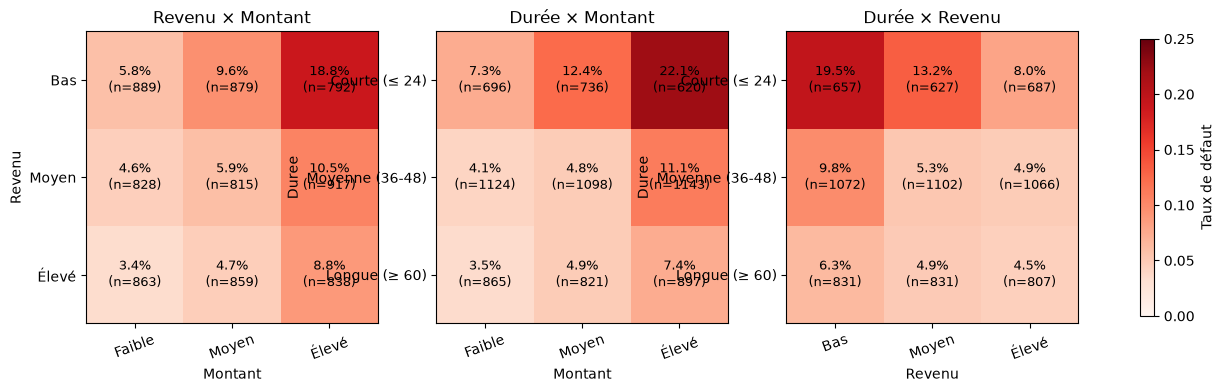

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

data = df.copy()

# 1. Une variable à la fois : taux de défaut et nombre de dossiers
print("=== Taux de défaut par durée ===")
print(data.groupby("duree_mois")["defaut"].agg(taux="mean", dossiers="count").round(3))

for col in ["revenu_annuel", "montant_pret"]:
    print(f"\n=== Taux de défaut par quintile de {col} ===")
    print(data.groupby(pd.qcut(data[col], 5), observed=True)["defaut"]
              .agg(taux="mean", dossiers="count").round(3))

# 2. Tranches pour les croisements
data["tranche_revenu"] = pd.qcut(data["revenu_annuel"], 3, labels=["Bas", "Moyen", "Élevé"])
data["tranche_montant"] = pd.qcut(data["montant_pret"], 3, labels=["Faible", "Moyen", "Élevé"])
data["tranche_duree"] = pd.cut(data["duree_mois"], bins=[0, 24, 48, 84],
                               labels=["Courte (≤ 24)", "Moyenne (36-48)", "Longue (≥ 60)"])

croisements = [
    ("tranche_revenu", "tranche_montant", "Revenu × Montant"),
    ("tranche_duree", "tranche_montant", "Durée × Montant"),
    ("tranche_duree", "tranche_revenu", "Durée × Revenu"),
]

# 3. Tableaux croisés et cartes de chaleur
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (ligne, colonne, titre) in zip(axes, croisements):
    taux = pd.pivot_table(data, values="defaut", index=ligne, columns=colonne,
                          aggfunc="mean", observed=True)
    effectifs = pd.pivot_table(data, values="defaut", index=ligne, columns=colonne,
                               aggfunc="count", observed=True)
    print(f"\n=== {titre} : taux de défaut ===\n{taux.round(3)}")
    print(f"--- {titre} : nombre de dossiers ---\n{effectifs}")

    im = ax.imshow(taux, cmap="Reds", vmin=0, vmax=0.25)
    ax.set_xticks(range(len(taux.columns)), taux.columns, rotation=20)
    ax.set_yticks(range(len(taux.index)), taux.index)
    ax.set_xlabel(colonne.replace("tranche_", "").capitalize())
    ax.set_ylabel(ligne.replace("tranche_", "").capitalize())
    ax.set_title(titre)
    for i in range(taux.shape[0]):
        for j in range(taux.shape[1]):
            ax.text(j, i, f"{taux.iloc[i, j]:.1%}\n(n={effectifs.iloc[i, j]})",
                    ha="center", va="center", fontsize=9)

fig.colorbar(im, ax=axes, label="Taux de défaut", shrink=0.8)
plt.show()